# SafeFlow — Next-Level Analysis: Predicting Congestion Onset

The simple time-series analysis showed that **stable traffic states are relatively easy to forecast**, while abrupt transitions—especially free flow → congestion—are much harder.

This notebook advances that finding in two stages:

1. **Verify the finding across the full northbound I-5 corridor**, rather than at one station.
2. **Reframe the operational task as congestion-onset classification**:

> Among stations that are currently free-flowing, which ones will become congested within the next 30 minutes?

We then test whether progressively richer information improves early warning:

- current local speed,
- recent local speed history,
- flow + occupancy,
- time-of-day information,
- verified upstream-station conditions.

The final chronological test set is created but remains **sealed**. All model comparison and threshold selection in this notebook use training/validation data only.

## 1. Imports and configuration

The notebook is designed for the finalized northbound I-5 corridor dataset.

`REGIME_THRESHOLD` reproduces the four-state regression diagnostic. The classifier then uses a cleaner onset definition with a gap between clear free flow and clear congestion. Threshold sensitivity is tested later.

In [1]:
from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif not (ROOT / "data").exists():
    for candidate in [ROOT.parent, ROOT.parent.parent]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            ROOT = candidate.resolve()
            break

RAW_DIR = ROOT / "data" / "raw" / "pems"
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Use the pre-extracted D12 freeway feature table and temporal folds created in earlier notebooks.
# This notebook no longer reads the raw corridor CSV directly.
DATA_FILE = None

TIMESTAMP_COL = "Timestamp"
STATION_COL = "Station"
SPEED_COL = "Avg Speed"
FLOW_COL = "Total Flow"
OCC_COL = "Avg Occupancy"
OBS_COL = "% Observed"

FREEWAY = 5
DIRECTION = "N"
FORECAST_MIN = 30

REGIME_THRESHOLD = 45.0
FREE_FLOW_THRESHOLD = 50.0
CONGESTED_THRESHOLD = 40.0
TARGET_MIN_OBSERVED = 80

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TARGET_RECALL = 0.80

# Optional file with columns: Station, corridor_order
# corridor_order must increase in the northbound travel direction.
FEATURE_FILE = PROCESSED_DIR / "main.parquet"
FOLDS_FILE = PROCESSED_DIR / "temporal_folds.json"
STATION_ORDER_FILE = PROCESSED_DIR / "i5_nb_station_order.csv"
# --------------------------------

print("Project root:", ROOT)
for label, file in [("Feature table", FEATURE_FILE), ("Temporal folds", FOLDS_FILE),
                    ("Northbound station order", STATION_ORDER_FILE)]:
    print(f"{label}: {'ready' if file.exists() else 'missing'} — {file}")
print("Inputs are loaded from disk; notebooks can use separate kernels.")

Project root: C:\Erdos\Project\safeflow
Feature table: ready — C:\Erdos\Project\safeflow\data\processed\main.parquet
Temporal folds: ready — C:\Erdos\Project\safeflow\data\processed\temporal_folds.json
Northbound station order: ready — C:\Erdos\Project\safeflow\data\processed\i5_nb_station_order.csv
Inputs are loaded from disk; notebooks can use separate kernels.


## 2. Load and verify the finalized corridor

In [2]:
if not FEATURE_FILE.exists():
    raise FileNotFoundError(f"Missing {FEATURE_FILE}. Run the export cell in data_and_features.ipynb first.")
corridor_source = pd.read_parquet(FEATURE_FILE)
rename_map = {
    "timestamp": TIMESTAMP_COL, "station": STATION_COL, "speed": SPEED_COL,
    "flow": FLOW_COL, "occupancy": OCC_COL, "pct_observed": OBS_COL,
    "direction": "Direction", "Direction of Travel": "Direction", "freeway": "Freeway #",
}
corridor = corridor_source.rename(columns=rename_map).copy()
required_columns = [TIMESTAMP_COL, STATION_COL, SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]
missing_columns = [c for c in required_columns + ["Direction"] if c not in corridor.columns]
if missing_columns:
    raise KeyError(f"Missing corridor columns in {FEATURE_FILE}: {missing_columns}")
corridor[TIMESTAMP_COL] = pd.to_datetime(corridor[TIMESTAMP_COL], errors="raise")
direction = corridor["Direction"].astype(str).str.upper().str.strip()
corridor = corridor.loc[direction.eq(DIRECTION)].copy()
if "Freeway #" in corridor.columns:
    corridor = corridor.loc[pd.to_numeric(corridor["Freeway #"], errors="coerce").eq(FREEWAY)].copy()
corridor = corridor.loc[:, required_columns].copy()
for column in [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]:
    corridor[column] = pd.to_numeric(corridor[column], errors="coerce")
duplicates = int(corridor.duplicated([STATION_COL, TIMESTAMP_COL]).sum())
if duplicates:
    # Local wall-clock timestamps can repeat at the autumn DST transition.
    corridor = corridor.groupby([STATION_COL, TIMESTAMP_COL], as_index=False)[
        [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]].mean()
if corridor.empty:
    raise ValueError("No northbound corridor observations remain after filtering")
corridor = corridor.sort_values([TIMESTAMP_COL, STATION_COL]).reset_index(drop=True)
print("Loaded:", FEATURE_FILE)
print("Duplicate station/timestamp rows averaged:", duplicates)
print("Date range:", corridor[TIMESTAMP_COL].min(), "to", corridor[TIMESTAMP_COL].max())
print("Stations:", corridor[STATION_COL].nunique(), "Rows:", len(corridor))
display(corridor.head())

Loaded: C:\Erdos\Project\safeflow\data\processed\main.parquet
Duplicate station/timestamp rows averaged: 0
Date range: 2023-01-02 06:00:00 to 2025-12-31 19:55:00
Stations: 46 Rows: 6032624


,Timestamp,Station,Avg Speed,Total Flow,Avg Occupancy,% Observed
0,2023-01-02 06:00:00,1205045,71.7,168.0,0.0298,80.0
1,2023-01-02 06:00:00,1205071,59.9,188.0,0.0359,0.0
2,2023-01-02 06:00:00,1205088,69.6,193.0,0.0293,80.0
3,2023-01-02 06:00:00,1205135,71.5,191.0,0.0285,100.0
4,2023-01-02 06:00:00,1205152,60.2,212.0,0.0394,100.0


**Data represented in these results.** The saved run contains **6,032,624 observations from 46 northbound mainline stations**, from January 2023 through December 2025, with no duplicate station/timestamp pairs. The source feature table is limited to weekdays, 06:00–19:55. The findings therefore describe this corridor and observation window, rather than all D12 traffic, weekends, or overnight conditions.

The numerical commentary below describes the saved run. Revisit it after changing inputs, thresholds, or temporal folds. The all-period descriptive charts include the later holdout dates; only the classifier comparisons below use the specified development validation period. No holdout model score is reported, but these descriptive plots should not be described as a completely unseen holdout.

## 3. PeMS observation-quality summary

,rows,fraction
% Observed,,
100,3505609,0.581108
<50,1747145,0.289616
50–<80,600914,0.099611
80–<100,178956,0.029665


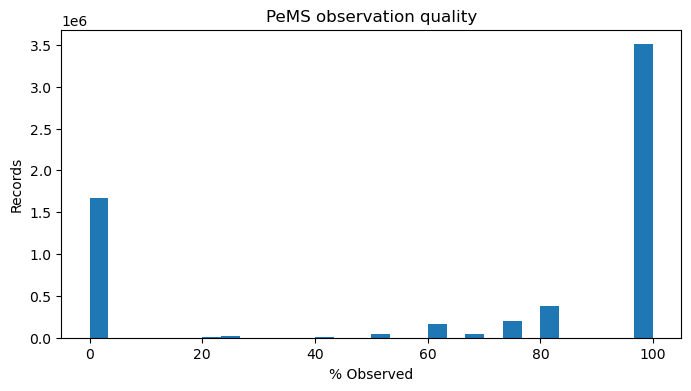

In [3]:
obs = pd.to_numeric(corridor[OBS_COL], errors="coerce")

quality_bins = pd.cut(
    obs,
    bins=[-np.inf, 50, 80, 99.999, np.inf],
    labels=["<50", "50–<80", "80–<100", "100"],
)

quality_summary = quality_bins.value_counts(dropna=False).to_frame("rows")
quality_summary["fraction"] = quality_summary["rows"] / len(corridor)
display(quality_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(obs.dropna(), bins=30)
ax.set_xlabel("% Observed")
ax.set_ylabel("Records")
ax.set_title("PeMS observation quality")
plt.show()

**Reading the observation-quality histogram.** Fully observed records account for **58.1%** of rows, while the lowest displayed bin contains **29.0%**. This substantial low-observation group makes label-quality filtering consequential. `% Observed` describes detector observation coverage; it is not the percentage confidence that a speed is correct. The classifier requires future observation coverage of at least 80%, but current inputs are not subject to the same cutoff.

The displayed bin labels have an edge-case caveat: `pd.cut` uses right-closed intervals here, so values exactly 50 and 80 enter the preceding bins. The final bin starts just above 99.999. These labels are approximate descriptions of the plotted groups; the model's separate `>= 80` target filter is exact.

# Part I — Verify the transition finding across the full corridor

Construct an exact 30-minute-ahead target with a station + timestamp merge rather than a blind row shift.

In [4]:
base_cols = [STATION_COL, TIMESTAMP_COL, SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]
base = corridor[base_cols].copy()

future = base[[STATION_COL, TIMESTAMP_COL, SPEED_COL, OBS_COL]].copy()
future[TIMESTAMP_COL] = future[TIMESTAMP_COL] - pd.Timedelta(minutes=FORECAST_MIN)
future = future.rename(columns={
    SPEED_COL: "target_speed_30min",
    OBS_COL: "target_observed_30min",
})

analysis = base.merge(
    future,
    on=[STATION_COL, TIMESTAMP_COL],
    how="inner",
    validate="one_to_one",
)
analysis = analysis.dropna(subset=[SPEED_COL, "target_speed_30min"]).copy()

print("Exact current/future pairs:", len(analysis))
display(analysis.head())

C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\2580527596.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future[TIMESTAMP_COL] = future[TIMESTAMP_COL] - pd.Timedelta(minutes=FORECAST_MIN)


Exact current/future pairs: 5817068


,Station,Timestamp,Avg Speed,Total Flow,Avg Occupancy,% Observed,target_speed_30min,target_observed_30min
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0,64.7,80.0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0,65.9,0.0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0,69.6,80.0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0,70.6,100.0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0,59.4,100.0


**What the paired sample means.** Exact station-and-time matching produces **5,817,068 usable current/future pairs**, about **96.4%** of the loaded observations. Rows without an available speed at either endpoint are excluded; the daily time window also removes origins whose +30-minute endpoint falls beyond the retained hours. Matching on timestamps prevents missing intervals from turning a six-row shift into the wrong forecasting horizon.

The outcome is congestion **at t + 30 minutes**. It does not establish whether congestion occurred at any earlier point within the next 30 minutes, nor whether congestion persisted for a minimum duration. Neighboring five-minute origins can refer to the same developing traffic episode, so row counts are not counts of independent congestion events.

## 4. Four traffic regimes across the corridor

,N
traffic_regime,
Free → Free,4852876
Free → Congested,183630
Congested → Congested,607266
Congested → Free,173296


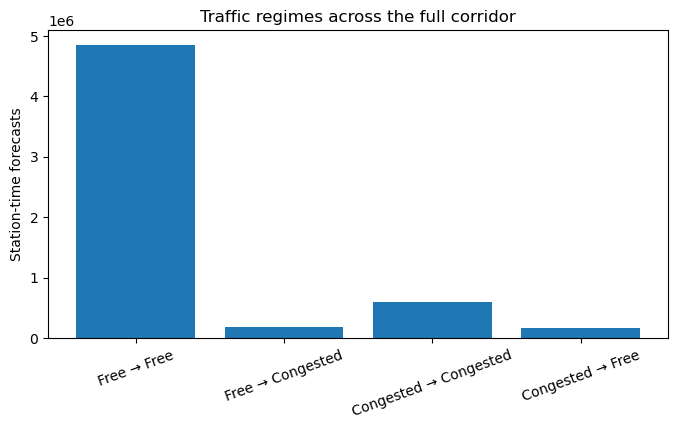

In [5]:
current_congested = analysis[SPEED_COL] < REGIME_THRESHOLD
future_congested = analysis["target_speed_30min"] < REGIME_THRESHOLD

analysis["traffic_regime"] = np.select(
    [
        (~current_congested) & (~future_congested),
        (~current_congested) & future_congested,
        current_congested & future_congested,
        current_congested & (~future_congested),
    ],
    [
        "Free → Free",
        "Free → Congested",
        "Congested → Congested",
        "Congested → Free",
    ],
    default="Unknown",
)

regime_order = [
    "Free → Free",
    "Free → Congested",
    "Congested → Congested",
    "Congested → Free",
]
regime_counts = analysis["traffic_regime"].value_counts().reindex(regime_order)
display(regime_counts.to_frame("N"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(regime_counts.index, regime_counts.values)
ax.set_ylabel("Station-time forecasts")
ax.set_title("Traffic regimes across the full corridor")
ax.tick_params(axis="x", rotation=20)
plt.show()

**Why the regime-count chart matters.** Free → Free dominates with **4,852,876 pairs (83.4%)**; persistent congestion contributes **607,266 (10.4%)**. Onset and recovery contribute only **183,630 (3.2%)** and **173,296 (3.0%)**, respectively. Thus **93.9%** of pairs remain on the same side of the 45 mph regime boundary. A low overall forecasting error can be driven by these stable cases while hiding much larger transition errors.

These are descriptive, all-period regime counts before the classifier's stricter free-flow/congestion gap and target-quality filter. They should not be equated with the later classification sample or its positive-class prevalence.

## 5. Persistence MAE/RMSE by regime

,Traffic regime,N,MAE_mph,RMSE_mph
3,Free → Free,4852876,2.06,3.22
2,Free → Congested,183630,12.35,14.54
0,Congested → Congested,607266,3.25,4.49
1,Congested → Free,173296,14.05,16.54


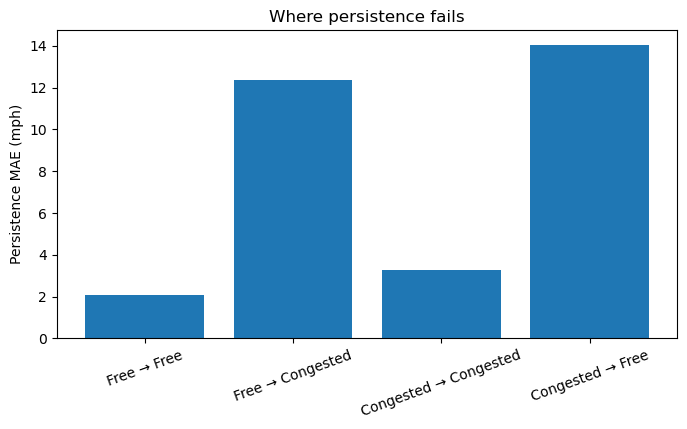

In [6]:
rows = []
for regime, subset in analysis.groupby("traffic_regime"):
    if regime == "Unknown" or len(subset) == 0:
        continue
    actual = subset["target_speed_30min"]
    forecast = subset[SPEED_COL]
    rows.append({
        "Traffic regime": regime,
        "N": len(subset),
        "MAE_mph": mean_absolute_error(actual, forecast),
        "RMSE_mph": np.sqrt(mean_squared_error(actual, forecast)),
    })

persistence_by_regime = pd.DataFrame(rows)
persistence_by_regime["Traffic regime"] = pd.Categorical(
    persistence_by_regime["Traffic regime"], categories=regime_order, ordered=True
)
persistence_by_regime = persistence_by_regime.sort_values("Traffic regime")
display(persistence_by_regime.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    persistence_by_regime["Traffic regime"].astype(str),
    persistence_by_regime["MAE_mph"],
)
ax.set_ylabel("Persistence MAE (mph)")
ax.set_title("Where persistence fails")
ax.tick_params(axis="x", rotation=20)
plt.show()

**Interpretation.** Persistence MAE is **2.06 mph** for Free → Free and **3.25 mph** for Congested → Congested, versus **12.35 mph** for onset and **14.05 mph** for recovery. Onset MAE is about **six times** stable free-flow MAE. The corresponding transition RMSE values, **14.54** and **16.54 mph**, put extra weight on larger misses. This supports reporting transitions separately from aggregate error.

Part of the contrast follows from defining transitions by crossing a speed boundary: a larger endpoint change necessarily hurts persistence. The result identifies its weakness, but does not by itself show that a learned model can predict those changes. These diagnostics span all available dates and have not applied the classifier's 80% target-observation filter.

## 6. Check whether onset difficulty is widespread across stations

In [ ]:
station_regime = (
    analysis.loc[analysis["traffic_regime"].isin(["Free → Free", "Free → Congested"])]
    .assign(abs_persistence_error=lambda x: (x["target_speed_30min"] - x[SPEED_COL]).abs())
    .groupby([STATION_COL, "traffic_regime"])
    .agg(N=("abs_persistence_error", "size"), MAE=("abs_persistence_error", "mean"))
    .reset_index()
)

station_mae = station_regime.pivot(index=STATION_COL, columns="traffic_regime", values="MAE")
station_n = station_regime.pivot(index=STATION_COL, columns="traffic_regime", values="N")

station_comparison = station_mae.copy()
station_comparison.columns = [f"{c} MAE" for c in station_comparison.columns]
for c in station_n.columns:
    station_comparison[f"{c} N"] = station_n[c]

display(station_comparison.head(20))
print("Median Free→Free station MAE:", station_mae.get("Free → Free", pd.Series(dtype=float)).median())
print("Median Free→Congested station MAE:", station_mae.get("Free → Congested", pd.Series(dtype=float)).median())

**How to assess the station comparison.** Compare Free → Congested MAE with Free → Free MAE within each station, together with their `N` columns. A consistent increase across well-supported stations would show that transition difficulty is widespread rather than driven by a few locations. A station with few transition rows gives a less stable estimate.

**No output is saved for this cell in the current notebook.** The pooled transition contrast above is measured, but a numerical claim about station medians or the fraction of stations showing that contrast must wait until this cell is run.

# Part II — Congestion-onset classification

Operational question:

> Given that the station is currently in free flow, will it be clearly congested 30 minutes later?

Definition used here:
- current speed ≥ `FREE_FLOW_THRESHOLD`
- positive: future speed ≤ `CONGESTED_THRESHOLD`
- negative: future speed ≥ `FREE_FLOW_THRESHOLD`
- ambiguous future speeds between thresholds are excluded

In [7]:
onset = analysis.loc[analysis[SPEED_COL] >= FREE_FLOW_THRESHOLD].copy()

onset["onset_label"] = np.where(
    onset["target_speed_30min"] <= CONGESTED_THRESHOLD,
    1,
    np.where(onset["target_speed_30min"] >= FREE_FLOW_THRESHOLD, 0, np.nan),
)

onset = onset.dropna(subset=["onset_label"]).copy()
onset["onset_label"] = onset["onset_label"].astype(int)

target_q = pd.to_numeric(onset["target_observed_30min"], errors="coerce")
onset = onset.loc[target_q >= TARGET_MIN_OBSERVED].copy()

print("Classification rows:", len(onset))
print("Positive onset cases:", onset["onset_label"].sum())
print("Onset prevalence:", onset["onset_label"].mean())
display(onset["onset_label"].value_counts().rename("N").to_frame())

Classification rows: 2905431
Positive onset cases: 37361
Onset prevalence: 0.012859021604712003


,N
onset_label,
0,2868070
1,37361


**Why these onset labels?** The classifier asks a narrower operational question than the 45 mph four-regime diagnostic: start from clearly free-flowing traffic (at least 50 mph), and flag clearly congested traffic (at most 40 mph) 30 minutes later. The 10 mph gap avoids treating borderline speeds as certain transitions; those ambiguous outcomes are excluded. Requiring at least 80% of target observations favors labels with adequate detector coverage. The resulting onset prevalence is only 1.29%, so later results must be read as rare-event detection, not ordinary accuracy.

## 7. When and where do onset events occur?

,onsets,eligible_rows,onset_rate
hour,,,
6,230,277057,0.000830
7,1374,261617,0.005252
8,1163,251938,0.004616
9,457,265161,0.001723
10,724,267989,0.002702
11,1151,262986,0.004377
12,2409,249693,0.009648
13,5460,229461,0.023795
14,12411,191041,0.064965


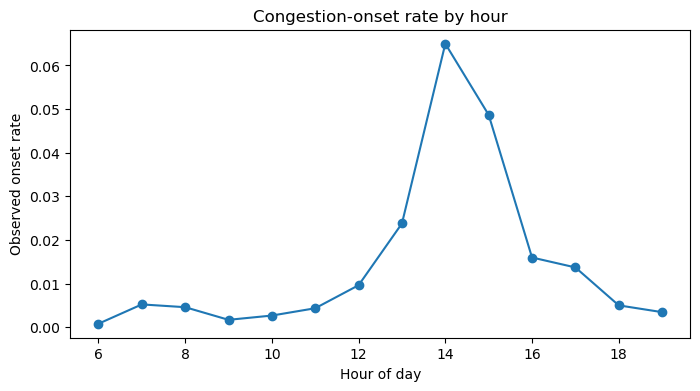

,onsets,eligible_rows,onset_rate
Station,,,
1205175,4375,69285,0.063145
1205215,3368,52167,0.064562
1205088,3214,43416,0.074028
1205375,3157,81855,0.038568
1205262,2767,37500,0.073787
1205341,2751,81625,0.033703
1212001,2475,61378,0.040324
1205380,2132,75588,0.028206
1205432,1711,60526,0.028269


In [8]:
onset["hour"] = onset[TIMESTAMP_COL].dt.hour

hourly_onset = onset.groupby("hour")["onset_label"].agg(["sum", "count", "mean"])
hourly_onset = hourly_onset.rename(columns={"sum":"onsets", "count":"eligible_rows", "mean":"onset_rate"})
display(hourly_onset)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly_onset.index, hourly_onset["onset_rate"], marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Observed onset rate")
ax.set_title("Congestion-onset rate by hour")
plt.show()

station_onset = (
    onset.groupby(STATION_COL)["onset_label"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum":"onsets", "count":"eligible_rows", "mean":"onset_rate"})
    .sort_values("onsets", ascending=False)
)
display(station_onset.head(20))

**Interpretation of hourly and station patterns.** The conditional onset rate peaks at **6.50% at 14:00** and **4.87% at 15:00**, versus **0.083% at 06:00**. The 14:00 hour also contains the largest count, **12,411 positive rows**. Each rate is among currently free-flowing, quality-eligible observations with an unambiguous future label, not the fraction of all traffic that is congested. Late rush-hour congestion can persist without producing another eligible onset.

Station **1205175** has the largest displayed count (**4,375**) and a rate of **6.31%**, while station **1205088** has fewer positives (**3,214**) but a higher rate (**7.40%**). Counts combine exposure and conditional risk; rates and sample sizes are needed for location comparisons. These all-period patterns motivate temporal and spatial predictors, but do not establish causation or unseen-period performance.

# Part III — Exact-lag feature engineering

All features are available at forecast time. Lags are joined by exact timestamp so missing detector intervals cannot silently change lag duration.

In [9]:
features = base.copy().rename(columns={
    SPEED_COL: "speed_now",
    FLOW_COL: "flow_now",
    OCC_COL: "occupancy_now",
    OBS_COL: "observed_now",
})

lag_source = base.copy()

def add_exact_lag(frame, source, columns, lag_min, suffix):
    lag = source[[STATION_COL, TIMESTAMP_COL] + columns].copy()
    lag[TIMESTAMP_COL] = lag[TIMESTAMP_COL] + pd.Timedelta(minutes=lag_min)
    lag = lag.rename(columns={c: f"{c}_{suffix}" for c in columns})
    return frame.merge(lag, on=[STATION_COL, TIMESTAMP_COL], how="left", validate="one_to_one")

for lag_min in [5, 10, 15, 30]:
    features = add_exact_lag(features, lag_source, [SPEED_COL], lag_min, f"lag_{lag_min}min")
for lag_min in [5, 15, 30]:
    features = add_exact_lag(features, lag_source, [FLOW_COL, OCC_COL], lag_min, f"lag_{lag_min}min")

features = features.rename(columns={
    f"{SPEED_COL}_lag_5min": "speed_lag_5",
    f"{SPEED_COL}_lag_10min": "speed_lag_10",
    f"{SPEED_COL}_lag_15min": "speed_lag_15",
    f"{SPEED_COL}_lag_30min": "speed_lag_30",
    f"{FLOW_COL}_lag_5min": "flow_lag_5",
    f"{FLOW_COL}_lag_15min": "flow_lag_15",
    f"{FLOW_COL}_lag_30min": "flow_lag_30",
    f"{OCC_COL}_lag_5min": "occ_lag_5",
    f"{OCC_COL}_lag_15min": "occ_lag_15",
    f"{OCC_COL}_lag_30min": "occ_lag_30",
})

speed_recent = ["speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30"]
features["speed_trend_15"] = features["speed_now"] - features["speed_lag_15"]
features["speed_recent_mean"] = features[speed_recent].mean(axis=1)
features["speed_recent_std"] = features[speed_recent].std(axis=1)
features["flow_trend_15"] = features["flow_now"] - features["flow_lag_15"]
features["occupancy_trend_15"] = features["occupancy_now"] - features["occ_lag_15"]

hour_fraction = features[TIMESTAMP_COL].dt.hour + features[TIMESTAMP_COL].dt.minute / 60
features["hour_sin"] = np.sin(2 * np.pi * hour_fraction / 24)
features["hour_cos"] = np.cos(2 * np.pi * hour_fraction / 24)
features["is_weekend"] = (features[TIMESTAMP_COL].dt.dayofweek >= 5).astype(int)

print("Feature table shape:", features.shape)
display(features.head())

C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\3647930243.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  lag[TIMESTAMP_COL] = lag[TIMESTAMP_COL] + pd.Timedelta(minutes=lag_min)
C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\3647930243.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  lag[TIMESTAMP_COL] = lag[TIMESTAMP_COL] + pd.Timedelta(minutes=lag_min)
C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\3647930243.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  lag[TIM

Feature table shape: (6032624, 24)


,Station,Timestamp,speed_now,flow_now,occupancy_now,observed_now,speed_lag_5,speed_lag_10,speed_lag_15,speed_lag_30,...,flow_lag_30,occ_lag_30,speed_trend_15,speed_recent_mean,speed_recent_std,flow_trend_15,occupancy_trend_15,hour_sin,hour_cos,is_weekend
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,71.7,NaN,NaN,NaN,1.0,6.123234e-17,0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,59.9,NaN,NaN,NaN,1.0,6.123234e-17,0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,69.6,NaN,NaN,NaN,1.0,6.123234e-17,0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,71.5,NaN,NaN,NaN,1.0,6.123234e-17,0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,60.2,NaN,NaN,NaN,1.0,6.123234e-17,0


**Reading the feature preview.** The **6,032,624 × 24** table preserves the original observation rows while adding exact-time history and time-of-day features. Missing lags in the first 06:00 rows are expected: the source excludes observations before 06:00, so the preceding 5–30 minutes are unavailable. Later gaps can also leave missing lags; the model pipelines learn median replacements from training data.

The short-history mean uses whichever history values are present, so at the start of the day it can reduce to current speed alone. `is_weekend` is always zero in this weekday-only source and adds no distinguishing information in this run.

## 8. Upstream-station features

`data/processed/i5_nb_station_order.csv` is exported by `data_and_features.ipynb` from metadata postmiles for northbound I-5 mainline stations. Order increases in the direction of travel; station IDs do not define physical order. Inspect metadata ordering before interpreting spatial results. If this optional file is absent, spatial models are skipped.

In [10]:
SPATIAL_FEATURES_AVAILABLE = False

if STATION_ORDER_FILE.exists():
    station_order = pd.read_csv(STATION_ORDER_FILE)
    required = {STATION_COL, "corridor_order"}
    missing = required - set(station_order.columns)
    if missing:
        raise ValueError(f"Station-order file missing columns: {missing}")

    station_order = (
        station_order[[STATION_COL, "corridor_order"]]
        .drop_duplicates()
        .sort_values("corridor_order")
    )
    station_order["upstream_station"] = station_order[STATION_COL].shift(1)
    station_map = station_order[[STATION_COL, "upstream_station"]].dropna()

    features = features.merge(station_map, on=STATION_COL, how="left", validate="many_to_one")

    upstream_now = features[[
        STATION_COL, TIMESTAMP_COL, "speed_now", "flow_now", "occupancy_now", "speed_lag_15"
    ]].copy()
    upstream_now = upstream_now.rename(columns={
        STATION_COL: "upstream_station",
        "speed_now": "upstream_speed_now",
        "flow_now": "upstream_flow_now",
        "occupancy_now": "upstream_occupancy_now",
        "speed_lag_15": "upstream_speed_lag_15",
    })

    features = features.merge(
        upstream_now,
        on=["upstream_station", TIMESTAMP_COL],
        how="left",
        validate="many_to_one",
    )
    features["upstream_speed_trend_15"] = features["upstream_speed_now"] - features["upstream_speed_lag_15"]
    SPATIAL_FEATURES_AVAILABLE = True
    print("Verified upstream spatial features created.")
else:
    print("No verified station-order file found; spatial feature set will be skipped.")

Verified upstream spatial features created.


## 9. Attach labels to the feature table

In [11]:
label_cols = [STATION_COL, TIMESTAMP_COL, "onset_label", "target_speed_30min", "target_observed_30min"]
model_data = features.merge(
    onset[label_cols],
    on=[STATION_COL, TIMESTAMP_COL],
    how="inner",
    validate="one_to_one",
)

print("Modeling rows:", len(model_data))
print("Onset prevalence:", model_data["onset_label"].mean())

Modeling rows: 2905431
Onset prevalence: 0.012859021604712003


# Part IV — Chronological split by unique timestamps

All stations at a given timestamp go into the same partition. This prevents splitting the same traffic moment across train and validation/test.

In [12]:
if not FOLDS_FILE.exists():
    raise FileNotFoundError(f"Missing {FOLDS_FILE}. Run the export cell in data_and_features.ipynb first.")
fold_config = json.loads(FOLDS_FILE.read_text(encoding="utf-8"))
if fold_config["forecast_minutes"] != FORECAST_MIN:
    raise ValueError("Temporal-fold forecast horizon does not match this notebook")
folds = fold_config["folds"]
model_fold = folds[0]  # development fold; row indices are rebuilt for THIS feature table
train_start = pd.Timestamp(fold_config["train_start"])
val_start, val_end = pd.Timestamp(model_fold["val_start"]), pd.Timestamp(model_fold["val_end"])
test_start, test_end = pd.Timestamp(fold_config["test_start"]), pd.Timestamp(fold_config["test_end"])
if not train_start < val_start < val_end <= test_start < test_end:
    raise ValueError("Temporal fold boundaries are not chronological")
time = model_data[TIMESTAMP_COL]
target_time = time + pd.Timedelta(minutes=FORECAST_MIN)
train_mask = (time >= train_start) & (target_time < val_start)
val_mask = (time >= val_start) & (target_time < val_end)
test_mask = (time >= test_start) & (target_time < test_end)
train_df, val_df = model_data.loc[train_mask].copy(), model_data.loc[val_mask].copy()
test_df = model_data.loc[test_mask].copy()
for name, part in [("TRAIN", train_df), ("VALIDATION", val_df)]:
    if part.empty:
        raise ValueError(f"{name} has no eligible observations for the selected fold")
    print(name, part[TIMESTAMP_COL].min(), "to", part[TIMESTAMP_COL].max(), "Rows:", len(part))
    print("Onset rate:", part["onset_label"].mean())
print("SEALED TEST:", test_start, "to", test_end, "Rows:", len(test_df))

C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\1429151927.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  target_time = time + pd.Timedelta(minutes=FORECAST_MIN)


TRAIN 2023-01-02 06:00:00 to 2023-06-30 19:25:00 Rows: 431692
Onset rate: 0.010820214412127166
VALIDATION 2023-07-03 06:00:00 to 2023-12-29 19:25:00 Rows: 309745
Onset rate: 0.013504657056611084
SEALED TEST: 2025-07-01 00:00:00 to 2026-01-01 00:00:00 Rows: 567685


**What the split permits us to conclude.** The first development fold trains on **431,692 rows from January–June 2023** and validates on **309,745 rows from July–December 2023**. Onset prevalence changes from **1.08% in training to 1.35% in validation**. Origins whose 30-minute targets cross a boundary are excluded, preventing training labels from reaching into validation.

The **567,685-row July–December 2025 holdout** is reserved for a later final model evaluation. Although four temporal folds are saved, this run uses only the first: the comparisons below are **single-fold validation results**, not averages across all years or confidence intervals. All stations at a given origin timestamp share the same partition.

## 10. Progressively richer feature sets

In [13]:
FEATURE_SETS = {
    "A_current_speed": ["speed_now"],
    "B_local_history": [
        "speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30",
        "speed_trend_15", "speed_recent_mean", "speed_recent_std",
        "hour_sin", "hour_cos", "is_weekend",
    ],
    "C_plus_flow_occupancy": [
        "speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30",
        "speed_trend_15", "speed_recent_mean", "speed_recent_std",
        "flow_now", "flow_lag_5", "flow_lag_15", "flow_lag_30", "flow_trend_15",
        "occupancy_now", "occ_lag_5", "occ_lag_15", "occ_lag_30", "occupancy_trend_15",
        "observed_now", "hour_sin", "hour_cos", "is_weekend",
    ],
}

if SPATIAL_FEATURES_AVAILABLE:
    FEATURE_SETS["D_plus_upstream"] = FEATURE_SETS["C_plus_flow_occupancy"] + [
        "upstream_speed_now", "upstream_speed_lag_15", "upstream_speed_trend_15",
        "upstream_flow_now", "upstream_occupancy_now",
    ]

for name, cols in FEATURE_SETS.items():
    print(name, ":", len(cols), "features")

A_current_speed : 1 features
B_local_history : 11 features
C_plus_flow_occupancy : 22 features
D_plus_upstream : 27 features


**Feature rationale.** Current speed is the minimal predictor. B adds exact 5–30 minute speed history, variability, trends, and cyclic hour encodings; C adds flow, occupancy, their histories, and current observation quality; D adds contemporaneous and lagged upstream measurements. These are information bundles, so the A → B gain cannot be attributed to history alone, nor B → C to flow alone. The weekend flag is constant because the source contains weekdays only.

All predictors use information at or before the forecast origin. Median imputation and scaling are learned on training data, while station order comes from metadata. Availability of an upstream column does not guarantee every row has a matched upstream observation.

# Part V — Logistic-regression early-warning baseline

Median imputation and scaling are fit on training data only. `class_weight='balanced'` compensates for rare onset events. Primary ranking metric: **PR-AUC (average precision)**.

In [14]:
def classification_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "PR_AUC": average_precision_score(y_true, prob),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }

logistic_models = {}
logistic_probs = {}
rows = []

for set_name, cols in FEATURE_SETS.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ])
    pipe.fit(train_df[cols], train_df["onset_label"])
    prob = pipe.predict_proba(val_df[cols])[:, 1]

    logistic_models[set_name] = pipe
    logistic_probs[set_name] = prob
    rows.append({"Model":"Logistic regression", "Feature set":set_name,
                 **classification_metrics(val_df["onset_label"], prob)})

logistic_results = pd.DataFrame(rows)
display(logistic_results.sort_values("PR_AUC", ascending=False).round(3))

,Model,Feature set,PR_AUC,ROC_AUC,Precision,Recall,F1
3,Logistic regression,D_plus_upstream,0.126,0.884,0.050,0.833,0.094
2,Logistic regression,C_plus_flow_occupancy,0.124,0.881,0.049,0.841,0.093
1,Logistic regression,B_local_history,0.119,0.854,0.048,0.779,0.091
0,Logistic regression,A_current_speed,0.060,0.818,0.042,0.705,0.080


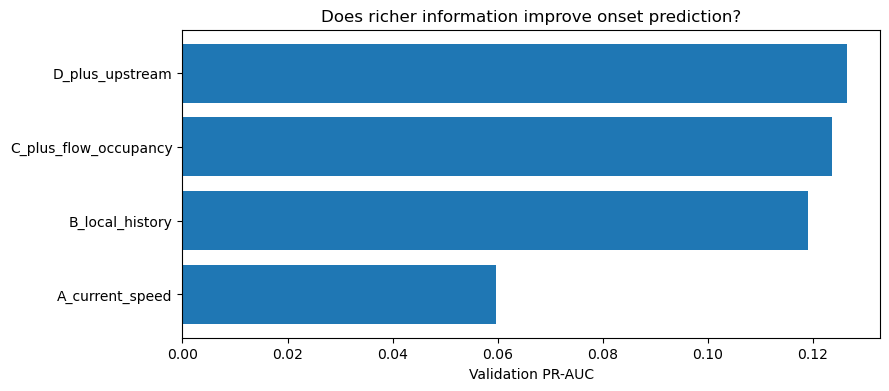

In [15]:
plot_results = logistic_results.sort_values("PR_AUC")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot_results["Feature set"], plot_results["PR_AUC"])
ax.set_xlabel("Validation PR-AUC")
ax.set_title("Does richer information improve onset prediction?")
plt.show()

**Reading the feature-comparison bars and metric table.** Logistic-regression average precision rises from **0.060 with current speed** to **0.119 with local history and calendar information**, then to **0.124 with flow, occupancy, and observation quality**, and **0.126 with upstream conditions**. The largest increment is A → B; because B adds both history and clock features, this comparison cannot isolate which of those two additions supplies the gain. C → D is only **0.002** and has no uncertainty estimate, so it is tentative evidence of incremental spatial value.

`PR_AUC` here is scikit-learn **average precision**, a summary of precision across recall levels. A non-informative ranking has a reference level near the validation positive fraction, **0.0135**. A value of 0.126 is well above that reference, but does not mean 12.6% accuracy or precision at every threshold. ROC-AUC measures positive-versus-negative ranking; its high values (up to 0.884) should be read alongside precision, which is only about **5%** for the best logistic model at the default 0.5 cutoff.

# Part VI — Nonlinear comparison with Random Forest

In [16]:
best_feature_set = logistic_results.sort_values("PR_AUC", ascending=False).iloc[0]["Feature set"]
best_features = FEATURE_SETS[best_feature_set]

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )),
])

rf.fit(train_df[best_features], train_df["onset_label"])
rf_prob = rf.predict_proba(val_df[best_features])[:, 1]
rf_metrics = classification_metrics(val_df["onset_label"], rf_prob)

best_logistic_row = logistic_results.sort_values("PR_AUC", ascending=False).iloc[0].to_dict()
model_comparison = pd.DataFrame([
    best_logistic_row,
    {"Model":"Random Forest", "Feature set":best_feature_set, **rf_metrics},
])
display(model_comparison.round(3))

,Model,Feature set,PR_AUC,ROC_AUC,Precision,Recall,F1
0,Logistic regression,D_plus_upstream,0.126,0.884,0.05,0.833,0.094
1,Random Forest,D_plus_upstream,0.322,0.918,0.17,0.659,0.270


**Logistic regression versus Random Forest.** Using the same upstream-augmented feature set and validation rows, Random Forest raises average precision from **0.126 to 0.322** (about **2.6×**) and ROC-AUC from **0.884 to 0.918**. This is consistent with useful nonlinear relationships or interactions, although it does not identify their causes.

At the default **0.5 cutoff**, Random Forest has **17.0% precision, 65.9% recall, and F1 0.270**; logistic regression has **5.0% precision, 83.3% recall, and F1 0.094**. Thus Random Forest ranks cases better and produces more selective warnings at this cutoff, but detects a smaller share of positives. These are not equal-recall comparisons: the next section adjusts the cutoff to meet the operational recall target.

# Part VII — Precision/recall and an operational warning threshold

The default probability threshold of 0.5 is arbitrary. Choose a threshold based on the warning tradeoff. Here we try to achieve at least `TARGET_RECALL`, then maximize precision among qualifying thresholds.

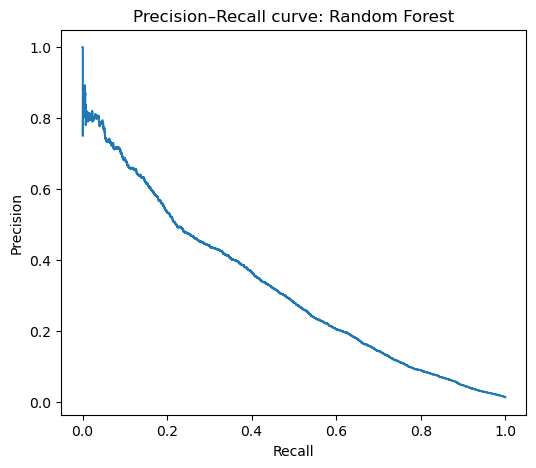

Chosen model: Random Forest
Validation PR-AUC: 0.32167598841326994
Operational threshold: 0.291339866881862


In [17]:
if rf_metrics["PR_AUC"] > best_logistic_row["PR_AUC"]:
    chosen_model_name = "Random Forest"
    chosen_prob = rf_prob
else:
    chosen_model_name = "Logistic regression"
    chosen_prob = logistic_probs[best_feature_set]

y_val = val_df["onset_label"].to_numpy()
precision, recall, thresholds = precision_recall_curve(y_val, chosen_prob)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall, precision)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Precision–Recall curve: {chosen_model_name}")
plt.show()

threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1],
})
eligible = threshold_table.loc[threshold_table["recall"] >= TARGET_RECALL].copy()

if len(eligible):
    operating_point = eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0]
    operational_threshold = float(operating_point["threshold"])
else:
    operational_threshold = 0.5

print("Chosen model:", chosen_model_name)
print("Validation PR-AUC:", average_precision_score(y_val, chosen_prob))
print("Operational threshold:", operational_threshold)

**Reading the precision–recall curve.** Moving toward greater recall generally accepts more warnings and lower precision; the full curve summarizes choices rather than one deployment policy. The selected Random Forest has average precision **0.3217**. The chosen score cutoff, **0.2913**, maximizes validation precision among cutoffs reaching at least 80% recall.

This cutoff was selected on the same validation data used to choose the feature set and model. Its measured performance is therefore a development estimate and may be optimistic; it needs confirmation across later folds and, after choices are frozen, on the holdout. Class weighting changes fitted scores, so a score of 0.291 is not established to mean a calibrated 29.1% real-world onset probability.

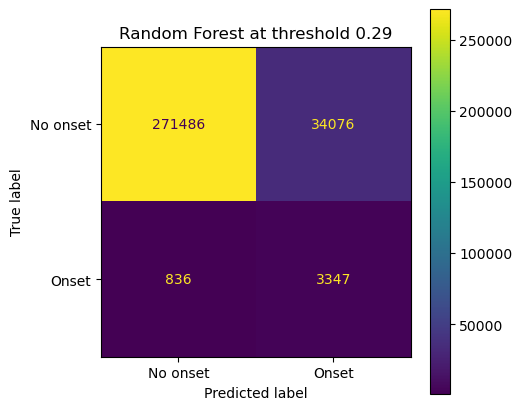

Precision: 0.08943697725997381
Recall: 0.8001434377241214
F1: 0.1608902562130462


In [18]:
chosen_label = (chosen_prob >= operational_threshold).astype(int)
cm = confusion_matrix(y_val, chosen_label)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["No onset", "Onset"]).plot(ax=ax, values_format="d")
ax.set_title(f"{chosen_model_name} at threshold {operational_threshold:.2f}")
plt.show()

print("Precision:", precision_score(y_val, chosen_label, zero_division=0))
print("Recall:", recall_score(y_val, chosen_label, zero_division=0))
print("F1:", f1_score(y_val, chosen_label, zero_division=0))

**Confusion matrix and warning burden.** Rows show actual classes and columns show predicted classes: the upper-right cell is false warnings, and the lower-left cell is missed onset rows. At the selected **0.2913 cutoff**, precision is **8.94%**, recall **80.01%**, and F1 **0.161**. About **9 of every 100 warnings** match an onset label; about **20 of every 100 positive rows** are missed. Equivalently, there are roughly **10.2 false-warning rows per true-positive row**.

Lowering the cutoff from 0.5 raises recall from **65.9% to 80.0%**, while reducing precision from **17.0% to 8.9%** and F1 from **0.270 to 0.161**. The selected policy prioritizes recall rather than maximum F1. These counts refer to station-time rows: consecutive warnings may belong to one episode, so an operational system would also need episode-level evaluation and alert grouping.

## 12. Visualize warning probability for a fixed validation window

C:\Users\abhis\AppData\Local\Temp\ipykernel_4516\3060749384.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end_day = start_day + pd.Timedelta(days=2)


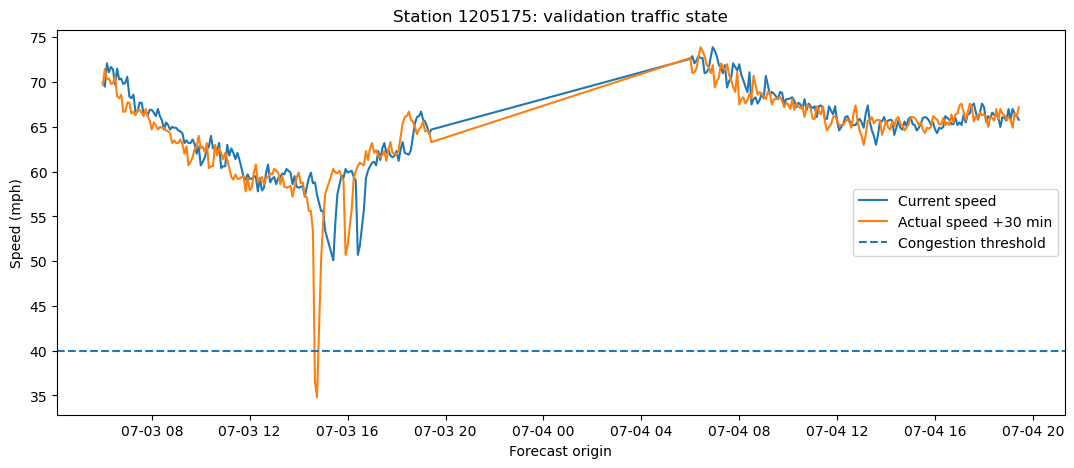

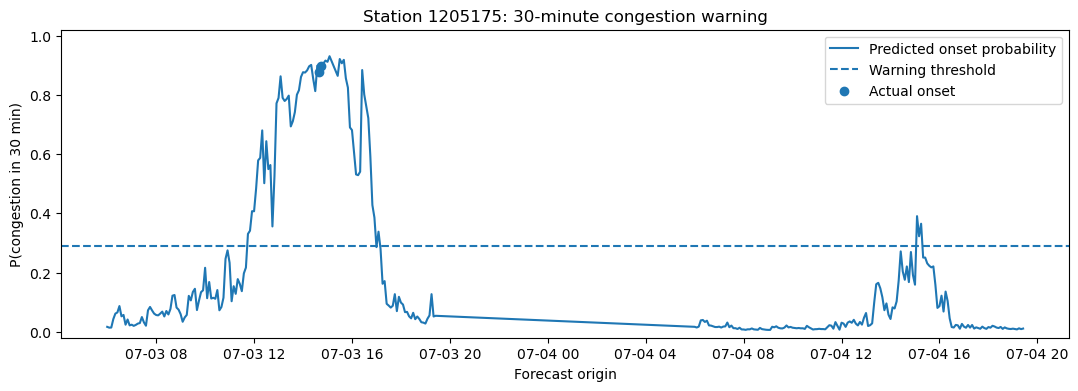

In [19]:
view = val_df[[STATION_COL, TIMESTAMP_COL, "speed_now", "target_speed_30min", "onset_label"]].copy()
view["predicted_onset_probability"] = chosen_prob

station_counts = view.groupby(STATION_COL)["onset_label"].sum().sort_values(ascending=False)
example_station = station_counts.index[0]
example = view.loc[view[STATION_COL] == example_station].sort_values(TIMESTAMP_COL).copy()

start_day = example[TIMESTAMP_COL].dt.normalize().min()
end_day = start_day + pd.Timedelta(days=2)
example = example.loc[(example[TIMESTAMP_COL] >= start_day) & (example[TIMESTAMP_COL] < end_day)]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(example[TIMESTAMP_COL], example["speed_now"], label="Current speed")
ax.plot(example[TIMESTAMP_COL], example["target_speed_30min"], label="Actual speed +30 min")
ax.axhline(CONGESTED_THRESHOLD, linestyle="--", label="Congestion threshold")
ax.set_xlabel("Forecast origin")
ax.set_ylabel("Speed (mph)")
ax.set_title(f"Station {example_station}: validation traffic state")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(example[TIMESTAMP_COL], example["predicted_onset_probability"], label="Predicted onset probability")
ax.axhline(operational_threshold, linestyle="--", label="Warning threshold")
actual_onsets = example.loc[example["onset_label"] == 1]
ax.scatter(actual_onsets[TIMESTAMP_COL], actual_onsets["predicted_onset_probability"], label="Actual onset")
ax.set_xlabel("Forecast origin")
ax.set_ylabel("P(congestion in 30 min)")
ax.set_ylim(-0.02, 1.02)
ax.set_title(f"Station {example_station}: 30-minute congestion warning")
ax.legend()
plt.show()

**Reading the two example-station plots.** The saved example is **station 1205175 on July 3–4, 2023**. In the upper plot, the orange line is the observed speed 30 minutes after each forecast origin, not a speed forecast. Its July 3 afternoon dip below 40 mph identifies positive endpoint outcomes. In the lower plot, model scores rise above the **0.291** warning cutoff around that afternoon period, including the marked positive cases. A smaller July 4 afternoon excursion crosses the warning line without marked positives, illustrating false alerts in this window.

Only origins meeting the free-flow, target-quality, and unambiguous-label rules appear. Lines bridge overnight and excluded intervals; the long connecting segments do **not** show continuously observed traffic or continuous model output. The station was chosen for having the most validation positives, so this is an illustrative case rather than a representative or randomly selected performance sample. The panel alone does not measure warning lead time or incident-level recall.

# Part VIII — Performance breakdowns

Check whether the warning model is consistent across time of day and stations rather than reporting only one overall PR-AUC.

In [20]:
val_diag = val_df[[STATION_COL, TIMESTAMP_COL, "target_observed_30min", "onset_label"]].copy()
val_diag["prob"] = chosen_prob
val_diag["prediction"] = chosen_label
val_diag["hour"] = val_diag[TIMESTAMP_COL].dt.hour

hour_rows = []
for hour, subset in val_diag.groupby("hour"):
    if subset["onset_label"].nunique() < 2:
        continue
    hour_rows.append({
        "hour": hour,
        "N": len(subset),
        "onsets": subset["onset_label"].sum(),
        "PR_AUC": average_precision_score(subset["onset_label"], subset["prob"]),
        "Recall": recall_score(subset["onset_label"], subset["prediction"], zero_division=0),
        "Precision": precision_score(subset["onset_label"], subset["prediction"], zero_division=0),
    })
hour_metrics = pd.DataFrame(hour_rows)
display(hour_metrics.round(3))

station_rows = []
for station_id, subset in val_diag.groupby(STATION_COL):
    if subset["onset_label"].nunique() < 2:
        continue
    station_rows.append({
        "Station": station_id,
        "N": len(subset),
        "onsets": subset["onset_label"].sum(),
        "PR_AUC": average_precision_score(subset["onset_label"], subset["prob"]),
        "Recall": recall_score(subset["onset_label"], subset["prediction"], zero_division=0),
    })
station_metrics = pd.DataFrame(station_rows).sort_values("PR_AUC", ascending=False)
display(station_metrics.head(20).round(3))

,hour,N,onsets,PR_AUC,Recall,Precision
0,6,30532,14,0.001,0.000,0.000
1,7,28131,207,0.165,0.280,0.112
2,8,27072,159,0.054,0.415,0.046
3,9,29221,55,0.008,0.255,0.010
4,10,29655,100,0.024,0.320,0.028
5,11,29361,111,0.035,0.459,0.024
6,12,27388,287,0.058,0.683,0.046
7,13,24196,667,0.238,0.934,0.083
8,14,19544,1341,0.481,0.966,0.167
9,15,15106,629,0.520,0.968,0.119


,Station,N,onsets,PR_AUC,Recall
19,1205380,7389,198,0.656,0.879
32,1212115,3575,48,0.651,0.979
31,1212001,3871,146,0.646,0.877
18,1205375,8655,331,0.645,0.943
17,1205341,8660,290,0.598,0.934
0,1205045,4829,146,0.531,0.774
13,1205262,1639,96,0.530,0.698
8,1205175,12970,832,0.503,0.865
11,1205215,6618,438,0.495,0.845
2,1205088,4533,381,0.453,0.722


**Where the validation model works better and worse.** At **14:00–15:00**, average precision is **0.481–0.520** and recall is **0.966–0.968** at the common cutoff. Performance is much weaker at **06:00** (14 positives, recall 0) and **19:00** (51 positives, recall 0.020). Overall 80% recall therefore does not imply consistent detection throughout the day; the many afternoon positives dominate the pooled result.

The displayed station table is sorted by average precision and shows only the **top 20**. For example, station 1205380 has average precision **0.656** with **198 positives**, while 1212115 has **0.651** with only **48**. Small-support estimates are less stable, and groups with only one class are omitted entirely. Compare subgroup average precision with each subgroup's own prevalence; prevalence differs across locations and hours. These are familiar-station temporal results, not evidence of generalization to unseen stations.

# Part IX — Observation-quality sensitivity

In [21]:
quality_rows = []
for threshold in [100, 80, 50, 0]:
    temp = analysis.loc[analysis[SPEED_COL] >= FREE_FLOW_THRESHOLD].copy()
    temp["label"] = np.where(
        temp["target_speed_30min"] <= CONGESTED_THRESHOLD,
        1,
        np.where(temp["target_speed_30min"] >= FREE_FLOW_THRESHOLD, 0, np.nan),
    )
    temp = temp.dropna(subset=["label"])
    q = pd.to_numeric(temp["target_observed_30min"], errors="coerce")
    temp = temp.loc[q >= threshold]
    quality_rows.append({
        "target_min_observed": threshold,
        "N": len(temp),
        "onsets": int(temp["label"].sum()),
        "onset_prevalence": temp["label"].mean(),
    })
quality_sensitivity = pd.DataFrame(quality_rows)
display(quality_sensitivity)

,target_min_observed,N,onsets,onset_prevalence
0,100,2642642,34244,0.012958
1,80,2905431,37361,0.012859
2,50,3255200,38996,0.011980
3,0,4579605,45866,0.010015


**Observation-quality sensitivity: coverage and label population.** Requiring **100%** target observation coverage retains **2,642,642 rows** and **34,244 positives** (1.296%). The **80%** cutoff retains **2,905,431 rows** and **37,361 positives** (1.286%): **262,789 extra rows** with nearly unchanged prevalence. Removing the cutoff retains **4,579,605 rows** but lowers prevalence to **1.002%**.

This makes 80% a useful coverage-versus-quality compromise for development. The table changes the included population; it does not prove that measurement quality causes a change in true congestion risk. **No models are refit at these alternative quality cutoffs**, so this table does not establish that predictive performance is robust to observation quality.

# Part X — Threshold-definition sensitivity

In [22]:
threshold_pairs = [(45, 40), (50, 40), (50, 45), (55, 45)]
threshold_rows = []

for free_thr, cong_thr in threshold_pairs:
    temp = analysis.loc[analysis[SPEED_COL] >= free_thr].copy()
    temp["label"] = np.where(
        temp["target_speed_30min"] <= cong_thr,
        1,
        np.where(temp["target_speed_30min"] >= free_thr, 0, np.nan),
    )
    temp = temp.dropna(subset=["label"])
    q = pd.to_numeric(temp["target_observed_30min"], errors="coerce")
    temp = temp.loc[q >= TARGET_MIN_OBSERVED]
    threshold_rows.append({
        "free_threshold": free_thr,
        "congested_threshold": cong_thr,
        "N": len(temp),
        "onsets": int(temp["label"].sum()),
        "onset_prevalence": temp["label"].mean(),
    })

threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity)

,free_threshold,congested_threshold,N,onsets,onset_prevalence
0,45,40,3108990,57819,0.018597
1,50,40,2905431,37361,0.012859
2,50,45,2947192,79122,0.026847
3,55,45,2633078,49218,0.018692


**Sensitivity to the operational speed definition.** The selected **50/40 mph** rule yields **37,361 positives among 2,905,431 rows** (1.286%). Raising the future congestion boundary to **45 mph**, while keeping current speed at least 50 mph, yields **79,122 positives** (2.685%)—about twice the prevalence because milder slowdowns now qualify. Using **45/40 mph** gives 1.860%, while **55/45 mph** gives 1.869%; each rule changes the starting population as well as the outcome definition.

These are user-chosen decision boundaries, not changes in posted speed limits. The table describes label sensitivity only: no classifier is retrained or evaluated under the alternative definitions. A different definition needs its own model comparison and warning-threshold selection.

## 15. Save validation/development results

In [23]:
date_tag = datetime.now().strftime("%Y-%m-%d")

logistic_results.to_csv(RESULTS_DIR / f"onset_logistic_feature_comparison_{date_tag}.csv", index=False)
model_comparison.to_csv(RESULTS_DIR / f"onset_model_comparison_{date_tag}.csv", index=False)
persistence_by_regime.to_csv(RESULTS_DIR / f"persistence_by_regime_{date_tag}.csv", index=False)
quality_sensitivity.to_csv(RESULTS_DIR / f"onset_quality_sensitivity_{date_tag}.csv", index=False)
threshold_sensitivity.to_csv(RESULTS_DIR / f"onset_threshold_sensitivity_{date_tag}.csv", index=False)

print("Saved validation/development results to:", RESULTS_DIR)

Saved validation/development results to: C:\Erdos\Project\safeflow\results


# Findings from the saved run

**Stable traffic dominates the sample, while transitions expose persistence's weakness.** Free → Free accounts for 83.4% of endpoint pairs, with 2.06 mph persistence MAE; onset MAE rises to 12.35 mph. This motivates a separate rare-transition task, while recognizing that the regime definition itself selects larger changes.

**Richer features improve validation ranking, with the largest model gain from Random Forest.** Logistic average precision rises from 0.060 to 0.126 across the feature bundles, and Random Forest reaches 0.322. The small upstream increment in the logistic comparison needs confirmation across temporal folds.

**High recall currently entails many false warnings.** The selected policy detects about 80% of positive station-time rows, but only 8.94% of warnings are true positives. Performance varies substantially across hours and stations. These results support further development; they do not yet establish a reliable operational alert service.

**Limits of the evidence.** Model selection and cutoff tuning use one July–December 2023 validation fold. The label checks the endpoint exactly 30 minutes ahead, the data cover weekday daytime mainline traffic, and sensitivity tables report changing label populations rather than retrained-model robustness. All-period exploratory plots include later holdout dates, although no final-holdout model score has been computed. Validate across the remaining development folds, assess calibration and episode-level warning burden, and freeze choices before final holdout scoring.

# Recommended next extension

Do **not** jump straight to an LSTM. If this notebook shows meaningful signal, next test:

1. 10-, 15-, 30-, and 45-minute warning horizons;
2. the nearest 2–3 upstream stations;
3. gradient boosting;
4. probability calibration;
5. a contiguous-station geographic holdout;
6. only after choices are frozen, evaluate one selected final model once on the sealed chronological test period.